In [3]:
# Import required libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("Tensorflow:", tf.__version__)
print("Numpy:", np.__version__)
print("Setup successful!")

Tensorflow: 2.21.0
Numpy: 2.5.4
Setup successful!


In [4]:
# Load the MNIST dataset

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Tetsing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Tetsing labels: (10000,)


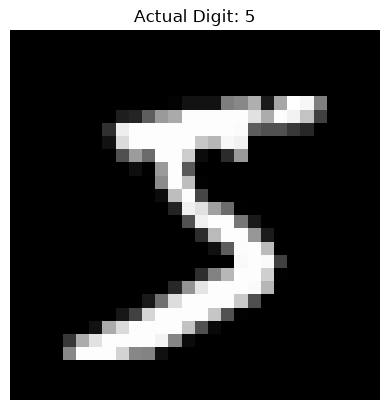

In [5]:
# Visualize a simple image

plt.imshow(x_train[0], cmap='gray')
# plt.imshow(x_train[0], cmap='viridis')
# plt.imshow (x_train[0], cmap='hot')
plt.title(f"Actual Digit: {y_train[0]}")
plt.axis('off')
plt.show()

In [6]:
# Explore pixel values

print("Image shape:", x_train[0].shape)
print("Pixel values:\n", x_train[0])
print("Minimum pixel value:", x_train[0].min())
print("Maximum pixel value:", x_train[0].max())

Image shape: (28, 28)
Pixel values:
 [[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0  

In [7]:
# Normalize the Image data

x_train_normalized = x_train / 255.0
x_test_normalized = x_test / 255.0

print("Original training range:", x_train.min(), "to", x_train.max())
print("Normalized training range:", x_train_normalized.min(), "to", x_train_normalized.max())

print("Original testing range:", x_test.min(), "to", x_test.max())
print("Normalized tetsing range:", x_test_normalized.min(), "to", x_test_normalized.max())

Original training range: 0 to 255
Normalized training range: 0.0 to 1.0
Original testing range: 0 to 255
Normalized tetsing range: 0.0 to 1.0


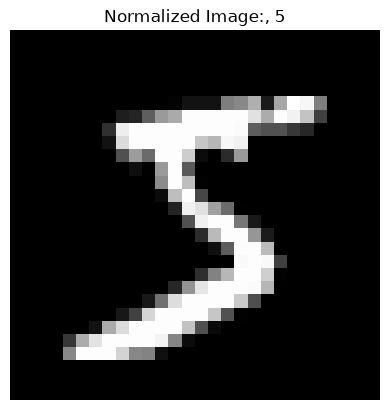

In [8]:
# Visualize a normalized image
plt.imshow(x_train_normalized[0], cmap='gray')
plt.title(f"Normalized Image:, {y_train[0]}")
plt.axis('off')
plt.show()

In [9]:
# Reshape images for the CNN

x_train_cnn = x_train_normalized.reshape(-1, 28, 28, 1)
x_test_cnn = x_test_normalized.reshape(-1, 28, 28, 1)

print("Training data shape:", x_train_cnn.shape)
print("Testing data shape:", x_test_cnn.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


In [10]:
# Build the CNN model

model = tf.keras.Sequential([
                              tf.keras.layers.Input(shape=(28, 28, 1)),
                              tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
                              tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
                              tf.keras.layers.Flatten(),
                              tf.keras.layers.Dense(128, activation='relu'),
                              tf.keras.layers.Dense(10, activation='softmax')
                             ])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Compile the CNN Model

model.compile(
              optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy']
             )

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
# Train the CNN Model

history = model.fit(
                    x_train_cnn,
                    y_train,
                    epochs=5,
                    batch_size=64,
                    validation_split=0.1
                   )

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.9426 - loss: 0.1921 - val_accuracy: 0.9803 - val_loss: 0.0699
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9814 - loss: 0.0620 - val_accuracy: 0.9857 - val_loss: 0.0499
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9884 - loss: 0.0389 - val_accuracy: 0.9877 - val_loss: 0.0431
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.9909 - loss: 0.0286 - val_accuracy: 0.9870 - val_loss: 0.0482
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.9940 - loss: 0.0198 - val_accuracy: 0.9855 - val_loss: 0.0605


In [13]:
# Evaluate the CNN Model

test_loss, test_accuracy = model.evaluate(
                                          x_test_cnn,
                                          y_test,
                                          verbose=1
                                         )

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9826 - loss: 0.0550
Test Loss: 0.05496653914451599
Test Accuracy: 98.25999736785889 %


In [14]:
# Predict a handwritten Digit

predictions =   model.predict(x_test_cnn[:5])

for i in range(5):
    predicted_digit = np.argmax(predictions[i])
    actual_digit = y_test[i]
    print("Actual Digit:", actual_digit)
    print("Predicted Digit:", predicted_digit)
    print("--------------------")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step
Actual Digit: 7
Predicted Digit: 7
--------------------
Actual Digit: 2
Predicted Digit: 2
--------------------
Actual Digit: 1
Predicted Digit: 1
--------------------
Actual Digit: 0
Predicted Digit: 0
--------------------
Actual Digit: 4
Predicted Digit: 4
--------------------


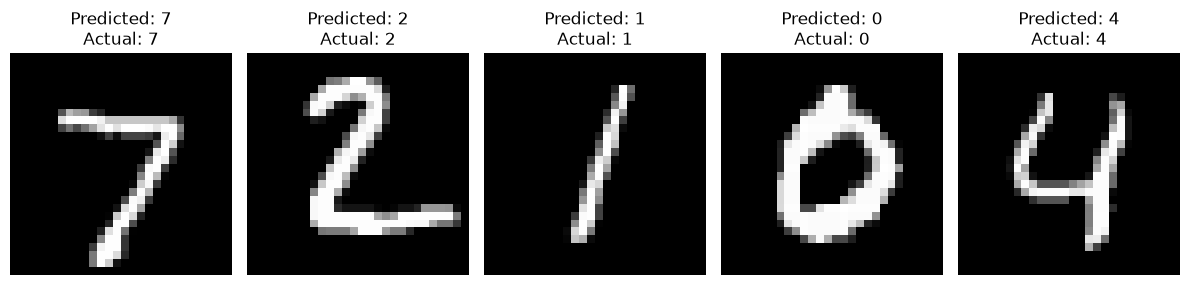

In [15]:
# Visualize the predictions

plt.figure(figsize=(12,5))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_test[i], cmap='gray')

    predicted_digit = np.argmax(predictions[i])
    actual_digit = y_test[i]

    plt.title(f"Predicted: {predicted_digit}\nActual: {actual_digit}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [16]:
# Generate Predictions for the Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

predictions_all = model.predict(x_test_cnn)
predicted_labels = np.argmax(predictions_all, axis=1)
cm = confusion_matrix(y_test, predicted_labels)
print("Confusion Matrix Shape:", cm.shape)
print(cm)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Confusion Matrix Shape: (10, 10)
[[ 973    0    2    0    0    0    3    1    1    0]
 [   0 1131    2    0    0    0    1    0    1    0]
 [   0    4 1019    0    1    0    0    6    2    0]
 [   0    0    6  982    0    9    1    2   10    0]
 [   0    2    1    0  977    0    0    0    0    2]
 [   1    0    1    3    0  862   21    0    1    3]
 [   2    3    1    0    2    1  949    0    0    0]
 [   1    6   10    0    0    0    0 1009    1    1]
 [   4    0    6    0    2    0    2    3  954    3]
 [   3    4    0    5   16    1    0    7    3  970]]


In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
print("Scikit-learn imported successfully!")

Scikit-learn imported successfully!


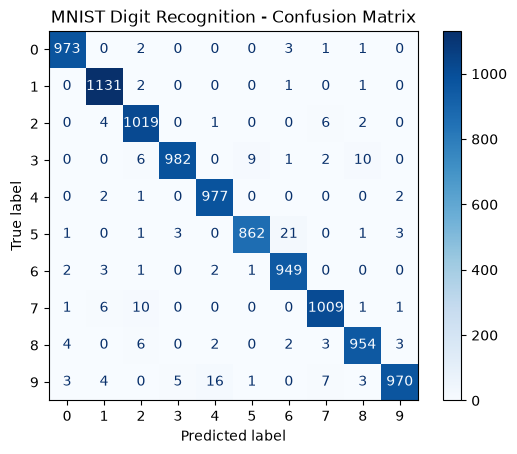

In [18]:
# Visualize the Confusion Matrix

display = ConfusionMatrixDisplay(
                                 confusion_matrix=cm,
                                 display_labels=np.arange(10)
                                )

display.plot(cmap='Blues', values_format='d')
plt.title("MNIST Digit Recognition - Confusion Matrix")
plt.show()

In [19]:
# Save the Trained CNN Model

model.save("handwritten_digit_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [20]:
# Load the Saved CNN Model

loaded_model = tf.keras.models.load_model(
                                          "handwritten_digit_model.keras"
                                         )    # loads the model we saved.

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [21]:
# Test the loaded model

test_image = x_test_cnn[0:1]
prediction = loaded_model.predict(test_image)

predicted_digit = np.argmax(prediction[0])
actual_digit = y_test[0]

# print("Test Image:", test_image)
# print("Prediction:", prediction)
print("Actual Digit:", actual_digit)
print("Predicted Digit:", predicted_digit)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
Actual Digit: 7
Predicted Digit: 7


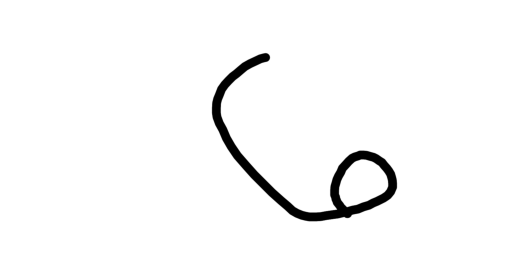

In [22]:
# Load & Display our own Handwritten Digit

import matplotlib.pyplot as plt

img = plt.imread("my_digit.png")

plt.imshow(img)
plt.axis("off")
plt.show()

In [23]:
# Inspect Image Properties

print("Image shape:", img.shape)
print("Data type:", img.dtype)
print("Minimum pixel value:", img.min())
print("Maximum pixel value:", img.max())

Image shape: (737, 1531, 4)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [24]:
# Convert Image to Grayscale
# (Got an error that's why we use "Pillow" library instead of "cv2")

# import cv2
# img_gray = cv2.imread("my_digit.png", cv2.IMREAD_GRAYSCALE)
# plt.imshow(img_gray, cmap="gray")
# plt.axis("off")
# plt.show()

In [25]:
# Testing 

from PIL import Image 

print("Pillow is installed!")

Pillow is installed!


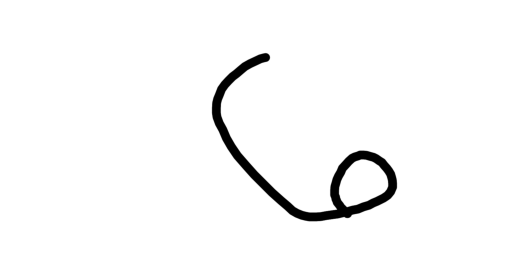

In [26]:
# Convert Image to Grayscale
# It gives an output not our expected output like black background and white digit!!
from PIL import Image
import matplotlib.pyplot as plt

img_gray = Image.open("my_digit.png").convert("L")

plt.imshow(img_gray, cmap="gray")
plt.axis("off")
plt.show()

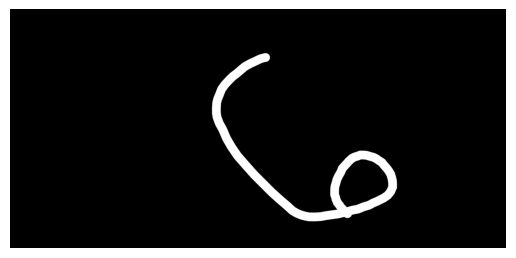

In [27]:
# Invert Image Colours

from PIL import ImageOps
import matplotlib.pyplot as plt

img_inverted = ImageOps.invert(img_gray)

plt.imshow(img_inverted, cmap="gray")
plt.axis("off")
plt.show()

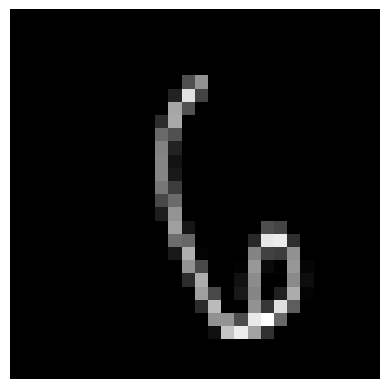

In [28]:
# Resize Image to 28*28 pixels

img_resized = img_inverted.resize((28,28))

plt.imshow(img_resized, cmap="gray")
plt.axis("off")
plt.show()

In [29]:
# Normalize Image Pixel Values

import numpy as np

img_array = np.array(img_resized, dtype=np.float32)
img_normalized = img_array / 255.0

print("Minimum pixel value:", img_normalized.min())
print("Maximum pixel value:", img_normalized.max())

Minimum pixel value: 0.0
Maximum pixel value: 0.8627451


In [30]:
# Reshape Image for CNN Prediction

img_cnn = np.array(img_normalized).reshape(1, 28, 28, 1)
print("Image shape for CNN:", img_cnn.shape)

Image shape for CNN: (1, 28, 28, 1)


In [31]:
# Predict our own Handwritten digit

prediction = loaded_model.predict(img_cnn)
predicted_digit = np.argmax(prediction[0])
print("Predicted Digit:", predicted_digit)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Predicted Digit: 1


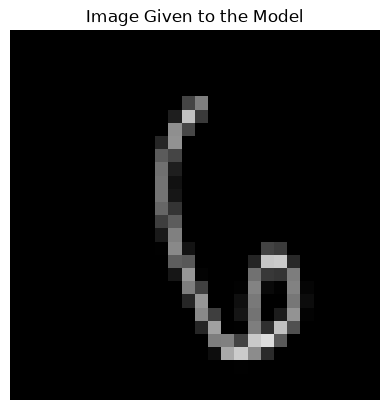

In [32]:
# Visualize prepared image before prediction

plt.imshow(img_cnn[0, :, :, 0], cmap="gray", vmin=0, vmax=1)
plt.title("Image Given to the Model")
plt.axis("off")
plt.show()

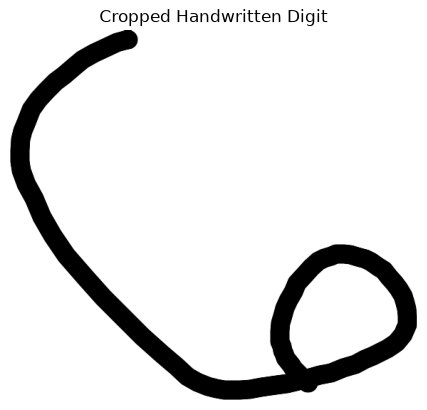

In [33]:
## Crop the handwritten digit 

import numpy as np
from PIL import Image

gray_array = np.array(img_gray)

# Find pixels that belong to the black digit
digit_pixels = gray_array < 128

# Find the digit's boundries
rows = np.where(digit_pixels.any(axis=1))[0]
cols = np.where(digit_pixels.any(axis=0))[0]

# Crop around the digit
cropped_array = gray_array[
                           rows[0]:rows[-1] + 1,
                           cols[0]:cols[-1] + 1
                          ]

img_cropped = Image.fromarray(cropped_array)

plt.imshow(img_cropped, cmap="gray")
plt.title("Cropped Handwritten Digit")
plt.axis("off")
plt.show()

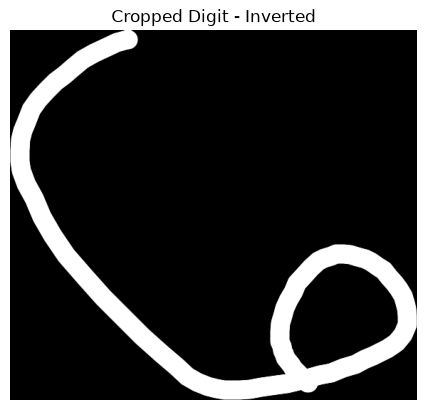

In [34]:
# Invert cropped image

from PIL import ImageChops

img_cropped_inverted = ImageOps.invert(img_cropped)

plt.imshow(img_cropped_inverted, cmap="gray")
plt.title("Cropped Digit - Inverted")
plt.axis("off")
plt.show()

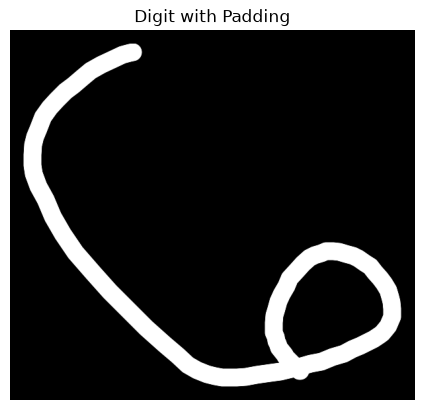

In [35]:
# Add padding around the digit

from PIL import ImageChops

img_padded = ImageOps.expand(
                             img_cropped_inverted,
                             border=20,
                             fill=0
                            )

plt.imshow(img_padded, cmap="gray")
plt.title("Digit with Padding")
plt.axis("off")
plt.show()

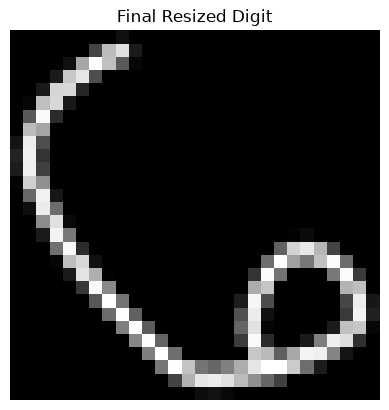

In [36]:
img_resized_final = img_padded.resize((28, 28))

plt.imshow(img_resized_final, cmap="gray")
plt.title("Final Resized Digit")
plt.axis("off")
plt.show()

In [37]:
# Normalize the Final Image

img_array_final = np.array(img_resized_final, dtype=np.float32)
img_normalized_final = img_array_final / 255.0

print("Image shape:", img_normalized_final.shape)
print("Minimum pixel value:", img_normalized_final.min())
print("Maximum pixel value:", img_normalized_final.max())

Image shape: (28, 28)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [38]:
# Reshape final image for CNN

img_cnn_final = img_normalized_final.reshape(1, 28, 28, 1)
print("Final image shape:", img_cnn_final.shape)

Final image shape: (1, 28, 28, 1)


In [39]:
# Predict the improved Handwritten image

prediction_final = loaded_model.predict(img_cnn_final)
predicted_digit_final = np.argmax(prediction_final[0])
print("Predicted Digit:", predicted_digit_final)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Predicted Digit: 5


In [40]:
# Analyze prediction probabilites

for digit, probability in enumerate(prediction_final[0]):
    print(f"Digit {digit}: {probability * 100:.2f}%")

Digit 0: 0.00%
Digit 1: 22.54%
Digit 2: 2.10%
Digit 3: 0.01%
Digit 4: 0.00%
Digit 5: 75.31%
Digit 6: 0.00%
Digit 7: 0.01%
Digit 8: 0.00%
Digit 9: 0.02%


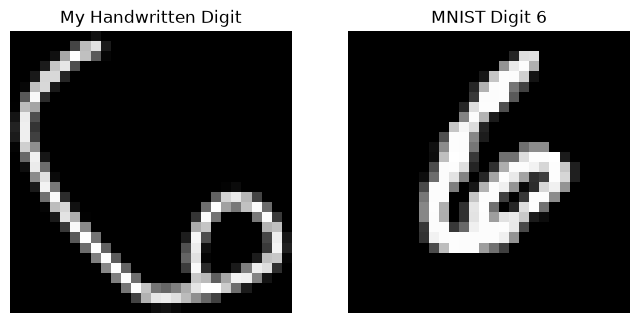

In [44]:
# Compare custom image with MNIST image

plt.figure(figsize=(8, 4))

## Our handwritten digit
plt.subplot(1, 2, 1)
plt.imshow(img_cnn_final[0, :, :, 0], cmap="gray")
plt.title("My Handwritten Digit")
plt.axis("off")

## MNIST training digit
plt.subplot(1, 2, 2)
plt.imshow(x_train_normalized[mnist_six], cmap="gray")
plt.title("MNIST Digit 6")
plt.axis("off")

plt.show()